In [1]:
# Anomaly Detection using Autoencoder

# 1. Import libraries
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# 2. Load and preprocess MNIST data
(x_train, _), (x_test, _) = keras.datasets.mnist.load_data()

x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

x_train = x_train.reshape(-1, 784)
x_test = x_test.reshape(-1, 784)

In [3]:
# 3. Encoder
input_img = keras.Input(shape=(784,))
encoded = layers.Dense(128, activation="relu")(input_img)
encoded = layers.Dense(32, activation="relu")(encoded)

In [5]:
# 4. Decoder
decoded = layers.Dense(128, activation="relu")(encoded)
decoded = layers.Dense(784, activation="sigmoid")(decoded)

# Create Autoencoder
autoencoder = keras.Model(input_img, decoded)

In [6]:
# 5. Compile model
autoencoder.compile(optimizer="adam",
                    loss="binary_crossentropy",
                    metrics=["accuracy"])

In [7]:
# 6. Train model
autoencoder.fit(x_train, x_train,
                epochs=10,
                batch_size=256,
                validation_data=(x_test, x_test))

Epoch 1/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.0100 - loss: 0.2304 - val_accuracy: 0.0115 - val_loss: 0.1549
Epoch 2/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - accuracy: 0.0098 - loss: 0.1364 - val_accuracy: 0.0121 - val_loss: 0.1210
Epoch 3/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.0092 - loss: 0.1159 - val_accuracy: 0.0106 - val_loss: 0.1094
Epoch 4/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - accuracy: 0.0099 - loss: 0.1078 - val_accuracy: 0.0112 - val_loss: 0.1039
Epoch 5/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.0118 - loss: 0.1035 - val_accuracy: 0.0124 - val_loss: 0.1003
Epoch 6/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.0126 - loss: 0.1003 - val_accuracy: 0.0125 - val_loss: 0.0975
Epoch 7/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - accuracy: 0.0127 - loss: 0.0979 - val_accuracy: 0.0129 - val_loss: 0.0956
Epoch 8/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.0128 - loss: 0.0962 - val_accu

In [8]:
# 7. Anomaly Detection
decoded_imgs = autoencoder.predict(x_test)

error = np.mean(np.square(x_test - decoded_imgs), axis=1)

threshold = np.percentile(error, 95)

anomalies = error > threshold

print("Anomaly Threshold:", threshold)
print("Number of anomalies:", np.sum(anomalies))

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
Anomaly Threshold: 0.020523071
Number of anomalies: 500


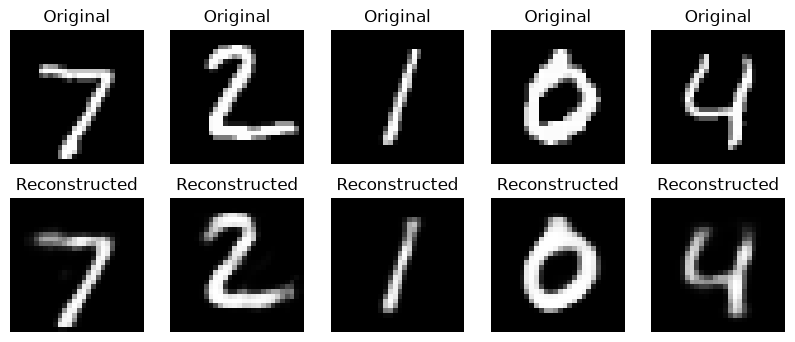

In [9]:
# 8. Display original and reconstructed images
plt.figure(figsize=(10, 4))

for i in range(5):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[i].reshape(28, 28), cmap="gray")
    plt.title("Original")
    plt.axis("off")

    plt.subplot(2, 5, i + 6)
    plt.imshow(decoded_imgs[i].reshape(28, 28), cmap="gray")
    plt.title("Reconstructed")
    plt.axis("off")

plt.show()

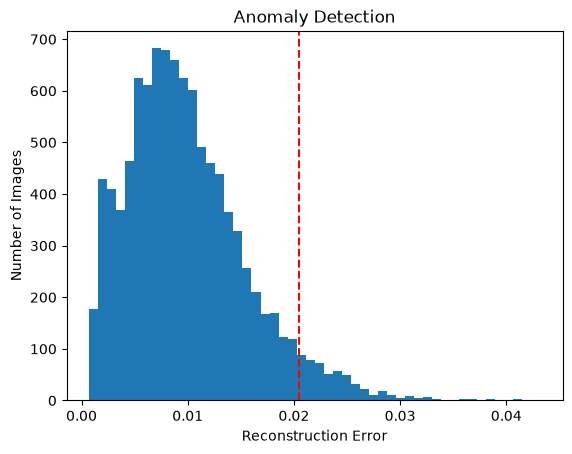

In [10]:
# 9. Plot anomaly error
plt.hist(error, bins=50)
plt.axvline(threshold, color="red", linestyle="--")
plt.xlabel("Reconstruction Error")
plt.ylabel("Number of Images")
plt.title("Anomaly Detection")
plt.show()